# Лабораторная работа 5. Позиционное кодирование и RoPE (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Понять, как трансформер получает информацию о порядке токенов и почему модели плохо работают на длинах контекста, которых не видели при обучении.

**Что нужно сдать:**
1. Единый интерфейс для пяти вариантов: NoPE, синусоидального, обучаемого, ALiBi и RoPE.
2. Численную проверку относительности RoPE и график затухания верхней границы.
3. Таблицу «кодирование × длина контекста» для символьной LM (экстраполяция длины).
4. Position interpolation и NTK-aware scaling для RoPE без дообучения и после короткого дообучения.
5. Тест «иголка в стоге сена» на синтетической задаче поиска.

**Теория.** RoPE поворачивает пары координат \((x_{2i}, x_{2i+1})\) на угол \(m\theta_i\), где \(\theta_i = b^{-2i/d}\), а \(m\) — позиция. В комплексной записи \(\tilde q_m = q\,e^{im\theta}\), \(\tilde k_n = k\,e^{in\theta}\), поэтому
\[
\mathrm{Re}\langle \tilde q_m, \tilde k_n\rangle = \mathrm{Re}\sum_i q_i \bar k_i\, e^{i(m-n)\theta_i},
\]
то есть скалярное произведение зависит только от разности позиций \(m - n\).

**Расширение контекста в \(s\) раз:**
- position interpolation: \(m \mapsto m/s\);
- NTK-aware scaling: \(b \mapsto b\, s^{d/(d-2)}\) — высокие частоты почти не меняются, низкие интерполируются.

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.6.0+cpu, device=cpu, FAST_DEV_RUN=True


## 1. Позиционные кодирования

In [2]:
def sinusoidal_pe(T, d):
    # TODO: ваш код
    positions = torch.arange(T, dtype=torch.float32)[:, None]
    frequencies = torch.exp(-math.log(10000.0) * torch.arange(0, d, 2).float() / d)
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(positions * frequencies)
    pe[:, 1::2] = torch.cos(positions * frequencies[:d // 2])
    return pe

def rope_angles(T, d, base=10000.0, scale=1.0):
    """Углы m*theta_i, форма (T, d/2). scale > 1 — position interpolation."""
    # TODO: ваш код
    if d % 2 or scale <= 0 or base <= 0:
        raise ValueError("RoPE требует чётную размерность и положительные base, scale")
    # float64 уменьшает ошибку вычисления углов на больших позициях.
    theta = base ** (-torch.arange(0, d, 2, dtype=torch.float64) / d)
    return torch.arange(T, dtype=torch.float64)[:, None] * theta / scale

def apply_rope(x, ang):
    """x: (..., T, d), ang: (T, d/2). Поворачивает пары (x[2i], x[2i+1])."""
    # TODO: ваш код
    if x.size(-1) % 2 or tuple(ang.shape) != (x.size(-2), x.size(-1) // 2):
        raise ValueError("Несовместимые размерности векторов и углов RoPE")
    angles = ang.to(x.device)
    c, s = angles.cos().to(x.dtype), angles.sin().to(x.dtype)
    pairs = x.reshape(*x.shape[:-1], -1, 2)
    even, odd = pairs[..., 0], pairs[..., 1]
    # cos/sin распространяются на размерности батча и голов.
    return torch.stack((even * c - odd * s, even * s + odd * c), dim=-1).flatten(-2)

def alibi_bias(T, n_head):
    """Смещение -m_h * (i - j) для j <= i; m_h = 2^{-8h/H}, h = 1..H. Форма (H, T, T)."""
    # TODO: ваш код
    position = torch.arange(T)
    distance = position[:, None] - position[None, :]
    slopes = 2.0 ** (-8.0 * torch.arange(1, n_head + 1) / n_head)
    bias = -slopes[:, None, None] * distance
    # Совмещаем штраф за расстояние с запретом смотреть в будущее.
    return bias.masked_fill(distance[None] < 0, float("-inf"))

### Проверка относительности RoPE

Для случайных \(q, k\) проверьте, что \(\langle R_m q, R_n k\rangle\) зависит только от \(m - n\), и постройте \(\frac{1}{d/2}\big|\sum_i e^{i r \theta_i}\big|\) в зависимости от расстояния \(r\) — величину, определяющую затухание верхней границы скалярного произведения при одинаковых \(q, k\).

m=   5, n=   2: <R_m q, R_n k> = -8.281104
m= 105, n= 102: <R_m q, R_n k> = -8.281103
m=1005, n=1002: <R_m q, R_n k> = -8.281103


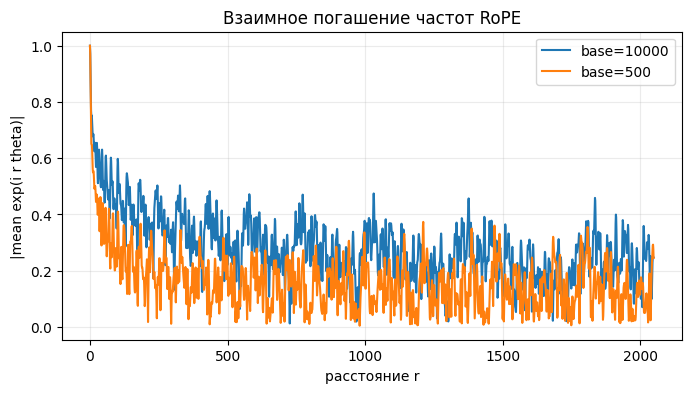

In [3]:
d = 64; torch.manual_seed(0); q, k = torch.randn(d), torch.randn(d)
ang = rope_angles(2048, d)
def rot_dot(m, n): return (apply_rope(q[None], ang[m:m + 1])[0] @ apply_rope(k[None], ang[n:n + 1])[0]).item()
for (m, n) in [(5, 2), (105, 102), (1005, 1002)]:
    print(f"m={m:4d}, n={n:4d}: <R_m q, R_n k> = {rot_dot(m, n):.6f}")
assert abs(rot_dot(5, 2) - rot_dot(1005, 1002)) < 1e-3

# TODO: ваш код (постройте |mean_i exp(i r theta_i)| для r = 0..2048 при base=10000 и base=500)
distances = torch.arange(2049, dtype=torch.float64)
plt.figure(figsize=(8, 4))
for base in (10000.0, 500.0):
    angles = rope_angles(len(distances), d, base=base)
    phase_kernel = torch.exp(1j * angles).mean(dim=-1).abs()
    plt.plot(distances.numpy(), phase_kernel.numpy(), label=f"base={base:g}")
plt.xlabel("расстояние r"); plt.ylabel("|mean exp(i r theta)|")
plt.title("Взаимное погашение частот RoPE"); plt.legend(); plt.grid(alpha=0.25)
plt.show()
# Фазовое ядро осциллирует, а не убывает на каждом шаге.
# Для произвольных q,k частоты имеют разные веса, поэтому кривая сама по себе
# не является универсальной поточечной верхней границей их скалярного произведения.


## 2. Трансформер с переключаемым позиционным кодированием

In [4]:
class PEAttention(nn.Module):
    def __init__(self, d_model, n_head, pe):
        super().__init__()
        self.h, self.dh, self.pe = n_head, d_model // n_head, pe
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False); self.o = nn.Linear(d_model, d_model, bias=False)
        self.rope_base, self.rope_scale = 10000.0, 1.0
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = (t.view(B, T, self.h, self.dh).transpose(1, 2) for t in self.qkv(x).split(C, 2))
        # TODO: ваш код (для rope поверните q и k; для alibi передайте смещение + каузальную маску через attn_mask)
        if self.pe == "rope":
            angles = rope_angles(T, self.dh, self.rope_base, self.rope_scale)
            q, k = apply_rope(q, angles), apply_rope(k, angles)
        if self.pe == "alibi":
            mask = alibi_bias(T, self.h).to(device=x.device, dtype=q.dtype)
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask[None])
        else:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.o(y.transpose(1, 2).reshape(B, T, C))

class PETransformer(nn.Module):
    def __init__(self, vocab, pe, d_model=128, n_head=4, n_layer=2, max_T=64, mlp=True):
        super().__init__()
        self.pe, self.max_T = pe, max_T
        self.emb = nn.Embedding(vocab, d_model)
        if pe == "learned": self.pos = nn.Parameter(torch.randn(max_T, d_model) * 0.02)
        self.attn = nn.ModuleList([PEAttention(d_model, n_head, pe) for _ in range(n_layer)])
        self.ln1 = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.mlp = nn.ModuleList([nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))
                                  if mlp else nn.Identity() for _ in range(n_layer)])
        self.use_mlp = mlp
        self.lnf, self.head = nn.LayerNorm(d_model), nn.Linear(d_model, vocab)
    def forward(self, x):
        T = x.size(1); h = self.emb(x)
        if self.pe == "sinusoidal": h = h + sinusoidal_pe(T, h.size(-1)).to(x.device)
        if self.pe == "learned":
            if T > self.max_T: raise ValueError("обучаемые позиции не определены за пределами обучающей длины")
            h = h + self.pos[:T]
        for a, l1, l2, m in zip(self.attn, self.ln1, self.ln2, self.mlp):
            h = h + a(l1(h))
            if self.use_mlp: h = h + m(l2(h))
        return self.head(self.lnf(h))
    def set_rope(self, base=10000.0, scale=1.0):
        for a in self.attn: a.rope_base, a.rope_scale = base, scale

PES = ["nope", "sinusoidal", "learned", "alibi", "rope"]

## 3. Экстраполяция длины на символьной LM

Обучите модели на окнах длины `T_TRAIN` и измерьте среднюю кросс-энтропию на окнах длины \(T_{train}\), \(2T_{train}\), \(4T_{train}\), \(8T_{train}\). Отдельно посчитайте loss только на позициях \(\ge T_{train}\) — это и есть качество экстраполяции.

In [5]:
text = load_shakespeare(); chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text]); ntr = int(0.9 * len(data)); train_d, val_d = data[:ntr], data[ntr:]
T_TRAIN = 64 if FAST_DEV_RUN else 128
STEPS = 400 if FAST_DEV_RUN else 4000

def lm_batch(d, T, B=32):
    ix = torch.randint(len(d) - T - 1, (B,))
    return torch.stack([d[i:i + T] for i in ix]).to(DEVICE), torch.stack([d[i + 1:i + T + 1] for i in ix]).to(DEVICE)

def train_lm(model, steps, T, lr=2e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    for s in range(steps):
        x, y = lm_batch(train_d, T); loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return model

@torch.no_grad()
def eval_lengths(model, lengths, n_windows=16):
    # TODO: ваш код (для каждой длины L — средний loss по всем позициям и по позициям >= T_TRAIN)
    was_training = model.training
    model.eval()
    results = {}
    # Одни начала окон для всех кодирований; используем только val_d.
    starts = torch.linspace(0, len(val_d) - max(lengths) - 1, n_windows).long()
    try:
        for L in lengths:
            if model.pe == "learned" and L > model.max_T:
                results[L] = (float("nan"), float("nan"))
                continue
            total, tail, tail_count = 0.0, 0.0, 0
            for start in starts:
                i = int(start)
                x = val_d[i:i + L][None].to(DEVICE)
                y = val_d[i + 1:i + L + 1].to(DEVICE)
                losses = F.cross_entropy(model(x)[0], y, reduction="none")
                total += losses.sum().item()
                if L > T_TRAIN:
                    tail += losses[T_TRAIN:].sum().item()
                    tail_count += L - T_TRAIN
            results[L] = (total / (n_windows * L),
                          tail / tail_count if tail_count else float("nan"))
    finally:
        model.train(was_training)
    return results

lengths = [T_TRAIN * m for m in (1, 2, 4, 8)]
lm_models, rows = {}, []
for pe in PES:
    set_seed(); t0 = time.time()
    lm_models[pe] = train_lm(PETransformer(len(chars), pe, max_T=T_TRAIN).to(DEVICE), STEPS, T_TRAIN)
    res = eval_lengths(lm_models[pe], lengths)
    rows.append({"PE": pe, **{f"L={L}": round(v[0], 3) for L, v in res.items()}, **{f"хвост L={L}": round(v[1], 3) for L, v in res.items() if L > T_TRAIN}})
    print(pe, f"{time.time() - t0:.0f} c")
import pandas as pd
pd.DataFrame(rows).set_index("PE")

nope 23 c


sinusoidal 25 c


learned 24 c


alibi 27 c


rope 24 c


,L=64,L=128,L=256,L=512,хвост L=128,хвост L=256,хвост L=512
PE,,,,,,,
nope,2.397,2.465,2.518,2.559,2.533,2.558,2.583
sinusoidal,2.102,2.694,3.002,3.118,3.287,3.303,3.263
learned,2.258,NaN,NaN,NaN,NaN,NaN,NaN
alibi,2.127,2.067,2.033,2.040,2.008,2.002,2.028
rope,2.014,2.108,2.450,2.859,2.202,2.595,2.979


## 4. Расширение контекста RoPE: position interpolation и NTK-aware scaling

Для RoPE-модели при длине \(L = s\,T_{train}\) сравните:
1. исходную модель;
2. position interpolation (`scale = s`);
3. NTK-aware scaling (`base = 10000 · s^{d/(d-2)}`).

Затем дообучите копии модели на длине \(L\) в течение короткого числа шагов (около 5% исходного обучения) с каждым вариантом и сравните снова.

In [6]:
import copy
s_ext = 4; L_ext = s_ext * T_TRAIN; d_head = 128 // 4
variants = {"исходная": dict(base=10000.0, scale=1.0), "PI": dict(base=10000.0, scale=float(s_ext)),
            "NTK": dict(base=10000.0 * s_ext ** (d_head / (d_head - 2)), scale=1.0)}
# TODO: ваш код (оцените варианты без дообучения и после короткого дообучения на длине L_ext)
fine_steps = max(1, round(0.05 * STEPS))
extension_rows = []
for name, settings in variants.items():
    # Независимые копии одних весов: исходная модель не меняется.
    candidate = copy.deepcopy(lm_models["rope"])
    candidate.set_rope(**settings)
    before = eval_lengths(candidate, [L_ext])[L_ext]
    # Seed выравнивает окна и порядок обновлений между вариантами.
    set_seed()
    train_lm(candidate, fine_steps, L_ext, lr=2e-4)
    after = eval_lengths(candidate, [L_ext])[L_ext]
    extension_rows.append({"вариант": name, "шагов дообучения": fine_steps,
                           "CE до": before[0], "CE хвост до": before[1],
                           "CE после": after[0], "CE хвост после": after[1]})
pd.DataFrame(extension_rows).set_index("вариант").round(4)


,шагов дообучения,CE до,CE хвост до,CE после,CE хвост после
вариант,,,,,
исходная,20,2.4132,2.5731,1.9832,2.0110
PI,20,3.1123,3.1156,2.3911,2.3911
NTK,20,2.1788,2.2571,1.9362,1.9493


## 5. «Иголка в стоге сена»

Задача: последовательность пар `ключ значение` и в конце запрос-ключ; нужно вернуть значение (как в ЛР 4). Обучите attention-only модели (2 слоя, без MLP) на длине 32 и проверьте точность на длинах 32, 64, 128 (в полном режиме и 256). Запрос может относиться к паре в любом месте контекста.

In [7]:
# При T=257 нужны 128 разных ключей и отдельные токены значений.
# Исходный словарь из 64 токенов не позволяет составить даже T=129.
VOCAB_KV = 256

def needle_batch(T, B=128):
    # TODO: ваш код (n=(T-1)//2 пар; ключи различны в примере; цель — значение пары с ключом-запросом)
    n = (T - 1) // 2
    n_keys = VOCAB_KV // 2
    if T % 2 == 0 or not 1 <= n <= n_keys:
        raise ValueError("Нужна длина 2*n+1 и достаточно различных ключей")
    # Случайные ранги выбирают ключи без возвращения внутри каждой строки.
    keys = torch.rand(B, n_keys).argsort(dim=1)[:, :n]
    values = torch.randint(n_keys, VOCAB_KV, (B, n))
    selected = torch.randint(n, (B,))
    x = torch.empty(B, T, dtype=torch.long)
    x[:, :-1:2], x[:, 1:-1:2] = keys, values
    x[:, -1] = keys[torch.arange(B), selected]
    y = values[torch.arange(B), selected]
    return x.to(DEVICE), y.to(DEVICE)

T_NEEDLE = 33
test_T = [33, 65, 129] if FAST_DEV_RUN else [33, 65, 129, 257]
rows = []
for pe in PES:
    set_seed(); m = PETransformer(VOCAB_KV, pe, n_layer=2, max_T=T_NEEDLE, mlp=False).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for s in range(800 if FAST_DEV_RUN else 4000):
        x, y = needle_batch(T_NEEDLE); loss = F.cross_entropy(m(x)[:, -1], y)
        opt.zero_grad(); loss.backward(); opt.step()
    r = {"PE": pe}
    with torch.no_grad():
        for T in test_T:
            try:
                x, y = needle_batch(T, B=512); r[f"T={T}"] = (m(x)[:, -1].argmax(-1) == y).float().mean().item()
            except ValueError:
                r[f"T={T}"] = float("nan")
    rows.append(r); print(r)
pd.DataFrame(rows).set_index("PE").round(3)

# В коротком прогоне точность на обучающей длине T=33 составляет около 5–8%.
# Это близко к выбору случайного значения из контекста: надёжный поиск не выучен.
# Поэтому более низкие числа на длинных окнах нельзя объяснять только
# позиционным кодированием. Для такого вывода сначала нужно доучить саму задачу.


{'PE': 'nope', 'T=33': 0.064453125, 'T=65': 0.04296875, 'T=129': 0.017578125}


{'PE': 'sinusoidal', 'T=33': 0.060546875, 'T=65': 0.033203125, 'T=129': 0.02734375}


{'PE': 'learned', 'T=33': 0.05859375, 'T=65': nan, 'T=129': nan}


{'PE': 'alibi', 'T=33': 0.052734375, 'T=65': 0.033203125, 'T=129': 0.03515625}


{'PE': 'rope', 'T=33': 0.078125, 'T=65': 0.0390625, 'T=129': 0.021484375}


,T=33,T=65,T=129
PE,,,
nope,0.064,0.043,0.018
sinusoidal,0.061,0.033,0.027
learned,0.059,NaN,NaN
alibi,0.053,0.033,0.035
rope,0.078,0.039,0.021


## Вопросы

1. Докажите свойство относительности RoPE. Почему RoPE применяется к \(q\) и \(k\), но не к \(v\)?

   Для двумерных поворотов R_m^T R_n = R_(n-m), поэтому q^T R_m^T R_n k определяется только разностью позиций. Это верно для фиксированных исходных q и k; сами векторы зависят от входа. Вращаем q и k, чтобы относительные позиции меняли веса внимания. Значения v сохраняют содержание, которое смешивается этими весами; их поворот не нужен для этого механизма.
2. Почему обучаемые позиционные эмбеддинги в принципе не экстраполируют, а синусоидальные формально определены, но на практике тоже плохо экстраполируют?

   У обучаемой таблицы нет строк для невиденных позиций. Синус и косинус можно посчитать на любой позиции, но сочетания их значений за пределами обучения могут быть непривычны модели. Определённость функции не гарантирует качество. NaN у learned в таблицах означает отсутствие позиционного вектора, а не бесконечный loss.
3. Как NoPE получает позиционную информацию в каузальной модели?

   Каузальная маска делает позиции неравноправными: у начала мало доступных токенов, у конца много. За несколько слоёв эта асимметрия и граничные эффекты могут передавать сведения о порядке. У NoPE нет явных позиционных векторов, но каузальность не делает модель полностью нечувствительной к позиции.
4. Объясните разницу между PI и NTK-aware scaling в терминах частот \(\theta_i\). Какие частоты «ломаются» при экстраполяции?

   В PI все позиции делятся на s, то есть каждая частота theta_i делится на s. В NTK меняется база: theta_i умножается на s^(-2*i/(d-2)). Для i=0 частота не меняется, а самая низкая делится на s. За пределами обучения фазы попадают в невиденные области; PI также меняет привычные короткие расстояния высоких частот. Это компромисс, а не гарантия улучшения без дообучения.
5. Как ALiBi реализует индуктивное смещение к локальности и почему оно мешает задаче поиска далёкой «иголки»?

   ALiBi вычитает из логита наклон головы, умноженный на расстояние. При прочих равных близкий ключ получает больший вес. Разные наклоны дают разную силу локальности, но у далёкой правильной пары большой штраф. На длинных контекстах содержательному сигналу нужно преодолеть этот штраф; сравнивать результаты следует вместе с точностью на обучающей длине.
